In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report


In [4]:
df = pd.read_csv('heart.csv')

# Step 4: Display Dataset Information
print("First 5 Records")
print(df.head())
print("\nDataset Shape:")
print(df.shape)
print("\nColumn Names:")
print(df.columns)
print("\nMissing Values:")
print(df.isnull().sum())


First 5 Records
   age  sex   chol  fbs  restecg  thalach  exang  oldpeak  slope   ca  thal  \
0   63  1.0  233.0  1.0        0    150.0      0      2.3    0.0  0.0     1   
1   37  1.0  250.0  0.0        1    187.0      0      3.5    0.0  0.0     2   
2   41  0.0  204.0  0.0        0    172.0      0      1.4    2.0  0.0     2   
3   56  1.0  236.0  0.0        1    178.0      0      0.8    2.0  0.0     2   
4   57  0.0  354.0  0.0        1    163.0      1      0.6    2.0  0.0     2   

   target  
0     1.0  
1     1.0  
2     1.0  
3     1.0  
4     1.0  

Dataset Shape:
(303, 12)

Column Names:
Index(['age', 'sex', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak',
       'slope', 'ca', 'thal', 'target'],
      dtype='str')

Missing Values:
age          0
sex          1
chol         1
fbs          2
restecg      0
thalach      1
exang        0
oldpeak      1
slope      209
ca           1
thal         0
target       1
dtype: int64


In [8]:
target_column = 'target'

# Check if target exists
if target_column not in df.columns:
    print("\nAvailable Columns:")
    print(list(df.columns))
    raise ValueError(f"Column '{target_column}' not found. Change target_column accordingly.")

# Step 6: Separate Features and Target
X = df.drop(target_column, axis=1)
y = df[target_column]


In [25]:
df = df.dropna(subset=[target_column]).copy()

In [26]:
df.isnull().sum()


age          0
sex          1
chol         1
fbs          2
restecg      0
thalach      1
exang        0
oldpeak      1
slope      209
ca           1
thal         0
target       0
dtype: int64

In [27]:
from sklearn.impute import SimpleImputer
imputer=SimpleImputer(strategy='median')
X=imputer.fit_transform(X)

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X,    y,    test_size=0.20,    random_state=42)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))



Training Samples: 241
Testing Samples: 61


In [30]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [31]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 9: Train KNN Model
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[float64](2,)","[0.,1.]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [32]:
y_pred = knn.predict(X_test_scaled)

# Step 11: Evaluation
accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:")
print(round(accuracy * 100, 2), "%")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))



Accuracy:
86.89 %

Confusion Matrix:
[[25  4]
 [ 4 28]]

Classification Report:
              precision    recall  f1-score   support

         0.0       0.86      0.86      0.86        29
         1.0       0.88      0.88      0.88        32

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.87      0.87      0.87        61



First 5 Records:
   age  sex   chol  fbs  restecg  thalach  exang  oldpeak  slope   ca  thal  \
0   63  1.0  233.0  1.0        0    150.0      0      2.3    0.0  0.0     1   
1   37  1.0  250.0  0.0        1    187.0      0      3.5    0.0  0.0     2   
2   41  0.0  204.0  0.0        0    172.0      0      1.4    2.0  0.0     2   
3   56  1.0  236.0  0.0        1    178.0      0      0.8    2.0  0.0     2   
4   57  0.0  354.0  0.0        1    163.0      1      0.6    2.0  0.0     2   

   target  
0     1.0  
1     1.0  
2     1.0  
3     1.0  
4     1.0  

Dataset Shape:
(303, 12)

Column Names:
['age', 'sex', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Missing Values:
age          0
sex          1
chol         1
fbs          2
restecg      0
thalach      1
exang        0
oldpeak      1
slope      209
ca           1
thal         0
target       1
dtype: int64

Rows with missing target labels: 1

Training Samples: 241
Testing Samples: 61



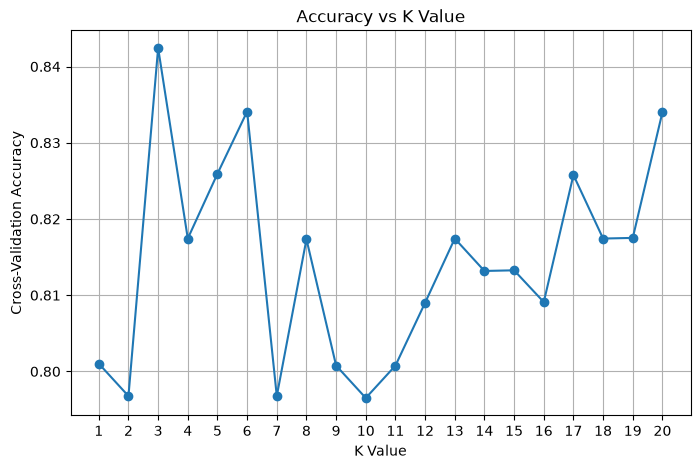

In [24]:
# Heart Disease Prediction using KNN

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Step 1: Load the dataset
df = pd.read_csv("heart.csv")

print("First 5 Records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

# Step 2: Identify the target column
target_column = "target"

if target_column not in df.columns:
    raise ValueError(
        f"Target column '{target_column}' not found. "
        f"Available columns: {list(df.columns)}"
    )

# Step 3: Remove rows with missing target labels
missing_targets = df[target_column].isna().sum()
print("\nRows with missing target labels:", missing_targets)

# We cannot train a supervised model without the correct target label
df = df.dropna(subset=[target_column]).copy()

# Step 4: Separate features and target
X = df.drop(columns=[target_column])
y = df[target_column]

# Convert categorical input features into numeric columns, if present
X = pd.get_dummies(X, dummy_na=True).astype(float)

# Step 5: Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# Step 6: Create a pipeline for missing values, scaling, and KNN
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

# Step 7: Find a suitable K using cross-validation on training data
max_k = min(20, max(1, int(len(X_train) * 0.8)))

param_grid = {
    "knn__n_neighbors": list(range(1, max_k + 1))
}

search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

search.fit(X_train, y_train)

best_k = search.best_params_["knn__n_neighbors"]

print("\nBest K Value:", best_k)
print("Best Cross-Validation Accuracy:",
      round(search.best_score_ * 100, 2), "%")

# Step 8: Predict the test records using the best model
best_model = search.best_estimator_
y_pred = best_model.predict(X_test)

# Step 9: Evaluate the model on the test set
accuracy = accuracy_score(y_test, y_pred)

print("\nTest Accuracy:")
print(round(accuracy * 100, 2), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Step 10: Plot cross-validation accuracy against K
k_values = list(range(1, max_k + 1))
accuracy_list = search.cv_results_["mean_test_score"]

plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracy_list, marker="o")

plt.xlabel("K Value")
plt.ylabel("Cross-Validation Accuracy")
plt.title("Accuracy vs K Value")
plt.xticks(k_values)
plt.grid(True)
plt.show()